### Project 1, Part 3: Data Analysis and Visualization
### Vanessa Molina
### 10/7/2026
### This program answers my data study questions through analysis and plots.
### Overall goal: While using Python, perform an exploratory data analysis of the CCM Computing Courses Entry Surveys. Provide insights that can help the Information Technologies department increase enrollment in computing classes.

### Section 1 - Import Statements
### First import pandas, the clean Majors Fall 2026 csv file, and matplotlib. 

In [26]:
### Import statement: pandas.
import pandas as pd
print(pd.__version__)

3.0.6


In [27]:
### Import statement: Fall 2026 cvs file.
datafile = "dataclean_major_survey_results_fall_2026.csv"
df = pd.read_csv(datafile)

In [28]:
#import matplotlib to create charts
import matplotlib.pyplot as plt

### Section 2 - Questions, Charts, and Analysis
### Using the cleaned Marjors Fall 2026 data, we can answer how to increase enrollment of computer classes at the County College of Morris. This is accomplished by creating charts and analysing the findings.

### ------------------------------------------------------------------------------------------------------------------------

### Question 1 - From the “how did you hear about County College of Morris” question, what was the highest ‘yes’ percentage from the choices?

In [22]:
hear_columns = ['hear_web', 'hear_social_media', 'hear_event', 'hear_family_friend', 'hear_current_student', 'hear_alumni', 'hear_teacher', 'hear_counselor', 'hear_ad', 'hear_employer', 'hear_bilboard', 'hear_tv', 'hear_radio', 'hear_other']

yes_percentages = (df[hear_columns] == 'Yes').mean() * 100 #get the percentage

yes_percentages = yes_percentages.round(2) # to round to 2 decimal points

yes_percentages.sort_values(ascending=False) #sort from highest to lowest

hear_family_friend      63.58
hear_web                43.93
hear_counselor          43.93
hear_teacher            43.93
hear_current_student    42.20
hear_event              26.59
hear_alumni             23.70
hear_social_media       19.65
hear_other              19.08
hear_ad                  6.94
hear_bilboard            5.78
hear_employer            4.62
hear_radio               3.47
hear_tv                  2.89
dtype: float64

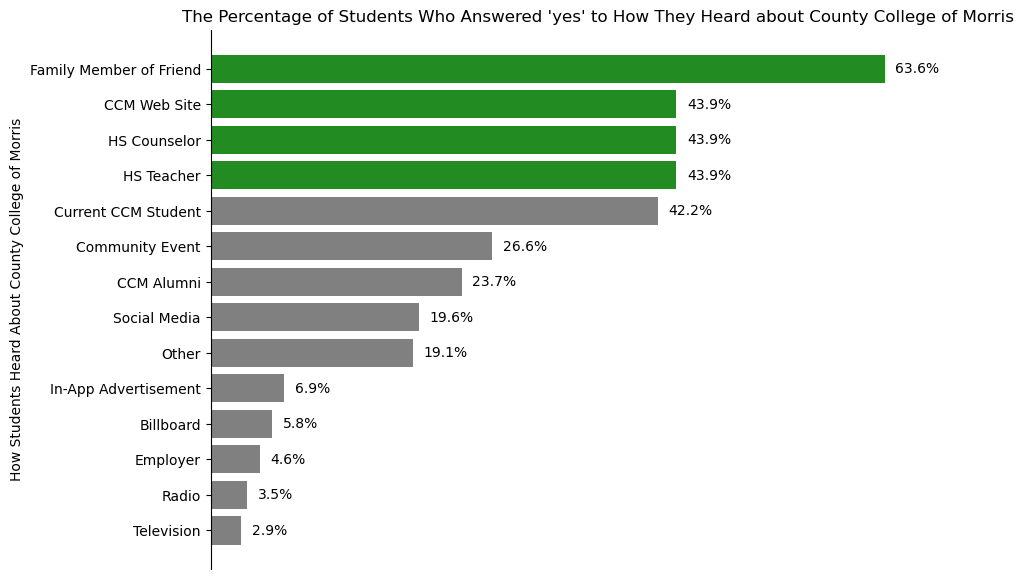

In [69]:
hear_percentage = {'Family Member of Friend': 63.58, 'CCM Web Site': 43.93, 'HS Counselor': 43.93, 'HS Teacher': 43.93, 
                   'Current CCM Student': 42.20, 'Community Event': 26.59, 'CCM Alumni': 23.70, 'Social Media': 19.65, 
                   'Other': 19.08, 'In-App Advertisement': 6.94, 'Billboard': 5.78, 'Employer': 4.62, 'Radio': 3.47, 'Television': 2.89}

df = pd.DataFrame(hear_percentage.items(), columns=['How Students Hear', 'Percentage'])#to make data into a DataFrame
                   
df = df.sort_values(by='Percentage', ascending=False) #to sort the DataFrame from lowest to highest. I used invert more down to make the highest at
                                                    #the top. When I did ascending=True, then the lowest 3 were highlighted and not the top 3. 

#to change the color of the top 3, better to highlight it.
colors = ['forestgreen' if i < 4 else 'grey'
          for i in range(len(df))]

#using 'ax.' to better match the textbook
fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(df['How Students Hear'], df['Percentage'], color=colors)

ax.spines[['right', 'top', 'bottom']].set_visible(False) #remove the boarder
ax.xaxis.set_visible(False) #(McDonald, 2023)

ax.invert_yaxis() #this puts the highest value at the top and the lowest at the bottom. 

ax.set_xlim(right=df['Percentage'].max() * 1.15) #To make room for the text to the right of the bars 

for bar in bars: #displays each bar’s percentage
    percentage = bar.get_width()
    ax.text(
        percentage + 1,
        bar.get_y() + bar.get_height() / 2,
        f'{percentage:.1f}%',
        ha='left',
        va='center',
        fontsize=10
    ) #(Deitel & Deitel, 2019)
ax.set_title("The Percentage of Students Who Answered 'yes' to How They Heard about County College of Morris")
ax.set_xlabel("The Percentage (%)") #added '%' to display exact values and prevent misinterpretation of the scale
ax.set_ylabel("How Students Heard About County College of Morris");

#Citation: McDonald, A. "7 Steps to Help You Make Your Matplotlib Bar Chart Beautiful." "Towards Data Science". 27 Mar. 2023,
            #https://towardsdatascience.com/7-steps-to-help-you-make-your-matplotlib-bar-charts-beautiful-f87419cb14cb/
        #Deitel, P. and Deitel, H. M. "Intro to Python for Computer Science and Data Science". Available from: VitalSource Bookshelf, Pearson Education (US), 2019.

#### Question 1 Analysis - Using a horizontal bar chart displays the percentage of students who have heard about CCM from friends and family (63.58%), CCM website (43.93%), high school counselor (43.93%) and high school teacher (43.93%). This is just the top 4 that are displayed on the bottom of the chart. It also shows us which advertisments we can move away from such as television, radio, and employer. Overall, providing more resources and focusing on advertising through word-of-mouth and online can increase awareness of the college.

### ------------------------------------------------------------------------------------------------------------------------

### Question 2 - What is the percentage of students that answered “some impact” or “high impact” in school-based environments (i.e. Middle/High school computing class)

In [29]:
impact_columns = ['impact_computing_class', 'impact_computing_club', 'impact_computing_competitions', 'impact_afterschool_computing', 'impact_summer_computing', 'impact_ap_computing','impact_dual_enrollment', 'impact_hs_teacher_counselor']

impact_percentage = ((df[impact_columns] == 'Some Impact') | (df[impact_columns] =='High Impact')).mean() * 100 #pandas Boolean to get the percentage

impact_percentage = impact_percentage.round(2) # round to 2 decimal points

impact_percentage.sort_values(ascending=False) #sort from highest to lowest.

impact_computing_class           48.55
impact_hs_teacher_counselor      32.37
impact_computing_competitions    29.48
impact_computing_club            18.50
impact_ap_computing              16.76
impact_dual_enrollment           15.61
impact_afterschool_computing     12.14
impact_summer_computing           7.51
dtype: float64

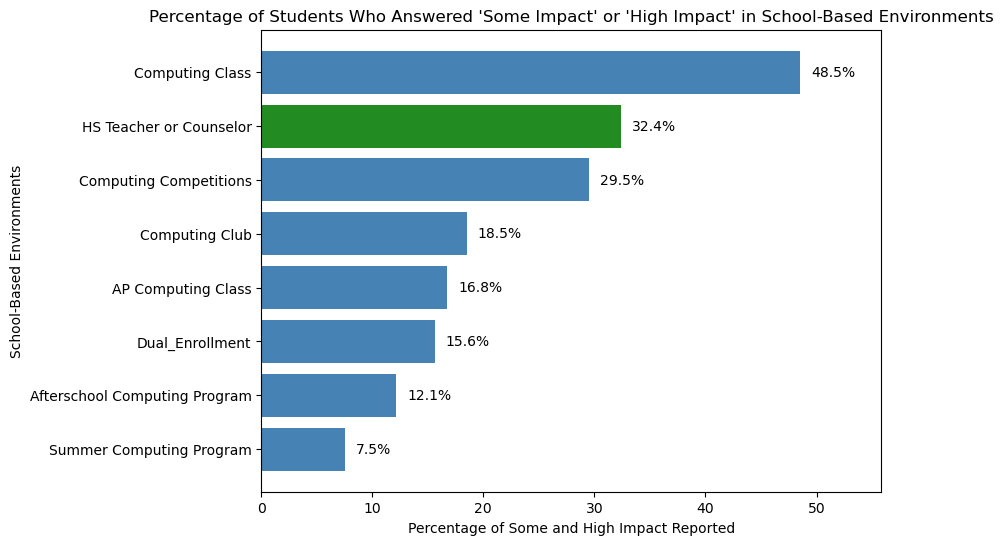

In [70]:
#used a horizontal bar chart because it is easier to read and compare the categories. Renamed the categories in impact_labels to make it easier to read.

environment_name = 'HS Teacher or Counselor'
highlight_color = 'forestgreen'
non_highlight = 'steelblue'

environment_impact = {'Computing Class': 48.55,'HS Teacher or Counselor': 32.37, 'Computing Competitions': 29.48,'Computing Club': 18.50,
'AP Computing Class': 16.76, 'Dual_Enrollment': 15.61,'Afterschool Computing Program': 12.14,'Summer Computing Program': 7.51}

df = pd.DataFrame(environment_impact.items(), columns=['Environment', 'Impact'])#to make data into a DataFrame

df['colors'] = df['Environment'].apply(lambda x: highlight_color if x == environment_name else non_highlight) #(McDonald, 2023)

df = df.sort_values(by='Impact', ascending=True) #sort from highest to lowest

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(df['Environment'], df['Impact'], color=df['colors'])

ax.set_xlim(right=df['Impact'].max() * 1.15) #To make room for the text to the right of the bars 

for bar in bars: #displays each bar’s percentage
    percentage = bar.get_width()
    ax.text(
        percentage + 1,
        bar.get_y() + bar.get_height() / 2,
        f'{percentage:.1f}%',
        ha='left',
        va='center',
        fontsize=10
    ) #(Deitel & Deitel, 2019)
    
plt.title("Percentage of Students Who Answered 'Some Impact' or 'High Impact' in School-Based Environments")
plt.ylabel("School-Based Environments")
plt.xlabel("Percentage of Some and High Impact Reported");

#### Question 2 Analysis -The use of a horizontal bar chart helps visualize how college students were impacted by activites and experiences from middle and high school. With this data, we can see how much of an influence specific people/programs were to current CCM students enrolled in computing courses and provide these influencers with advertisements and examples of work accomplished by CCM students to share with middle and high school students. From the chart, we can take a closer look at high school teacher or counselor as they are placed 2nd in some or high impact and also tied for 2nd in "The Percentage of Students Who Answered 'yes' to How They Heard about County College of Morris" chart. Because they were on both charts, it shows the influence they have on a student's decision to attend CCM and be a computing major.

### ------------------------------------------------------------------------------------------------------------------------

### Question 3 - What were the top 3 motivations of students obtaining a computing degree/certification?

In [30]:
motivation_columns = ['motivation_job', 'motivation_program_transfer', 'motivation_hs_credit', 'motivation_career_advancement', 'motivation_career_change', 'motivation_professional_development', 'motivation_job_displacement', 'motivation_relocation', 'motivation_current_tech', 'motivation_certifications', 'motivation_financial', 'motivation_personal_enrichment']

top_motivation = (df[motivation_columns] == 'Yes').sum() #get the sum of each column that answered 'yes'

top_motivation.sort_values(ascending=False).head(4) # sort from highest to lowest and then show the top 4

motivation_job                         96
motivation_personal_enrichment         85
motivation_professional_development    81
motivation_career_advancement          81
dtype: int64

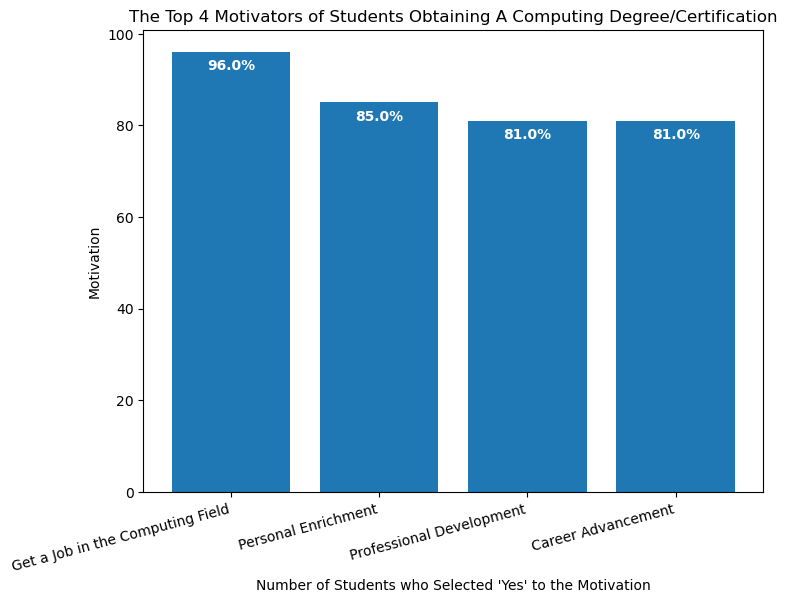

In [96]:
motivation_labels = ['Get a Job in the Computing Field', 'Personal Enrichment', 'Professional Development', 'Career Advancement']
motivation_values = [96, 85, 81, 81]

fig, ax = plt.subplots(figsize=(8, 6))

bars = ax.bar(motivation_labels, motivation_values)

ax.bar_label(bars, padding=-15, color='white', 
             fontsize=10, label_type='edge', fmt='%.1f%%',
            fontweight='bold') #(McDonald, 2023)

plt.title("The Top 4 Motivators of Students Obtaining A Computing Degree/Certification")
plt.xlabel("Number of Students who Selected 'Yes' to the Motivation")
plt.ylabel("Motivation")

plt.xticks(rotation=15, ha='right'); #rotate x-axis labels (PythonCharts.com, 2019)

#### Question 3 Analysis - The use of this bar chart is for us to see what motivates the students at CCM to pursue a computing degree or certification. This data help us appeal to high school seniors, incoming freshman, and current CCM students by allowing us to highlight the benefits that come with this degree and/or certification. Appealing towards a person's want for a job in the computing field or personal enrichment can be showcased in advertisements.

### ------------------------------------------------------------------------------------------------------------------------

### Question 4 - What gender has the lowest percentage of enrollment?

In [32]:
gender = df[['gender']]
gender.value_counts(normalize=True, ascending=True) * 100 # used value_count to count a string, normalize returns proprotions, and ascending=true sorts from lowest to highest
### used pandas.pydata.org for help with this one. Citation is below. 

gender           
Prefer not to say     2.312139
Non-binary            3.468208
Woman                20.809249
Man                  73.410405
Name: proportion, dtype: float64

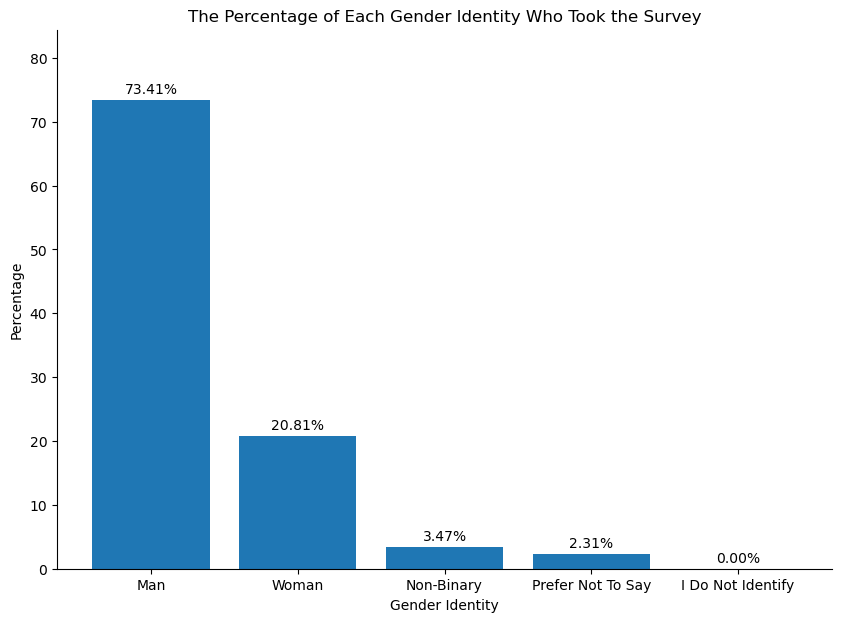

In [99]:
gender_values = {'Woman': 20.81, 'Man': 73.41, 'Non-Binary': 3.47, 'I Do Not Identify': 0, 'Prefer Not To Say': 2.31}

df = pd.DataFrame(gender_values.items(), columns=['Gender Identity', 'Percentage'])#to make data into a DataFrame

df = df.sort_values(by='Percentage', ascending=False) #sort from highest to lowest

fig, ax = plt.subplots(figsize=(10, 7))

bars = ax.bar(df['Gender Identity'], df['Percentage'])

ax.spines[['right', 'top']].set_visible(False) #remove the top and right sides of the boarder

ax.set_ylim(0, df['Percentage'].max() * 1.15)

for bar in bars:
    percentage = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        percentage + 0.5,
        f'{percentage:.2f}%',
        ha='center',
        va='bottom',
        fontsize=10
    )

plt.title("The Percentage of Each Gender Identity Who Took the Survey")
plt.xlabel("Gender Identity")
plt.ylabel("Percentage");

#### Question 4 Analysis - From this bar chart, we can see that the majority of students who completed this survey identify as men with a percentage of 73.41. From this report, 20.81% who completed this survey identify as women, 3.47% as non-binary, and 2.31% prefer not to say. Those that do not identify were 0%. From this we can say that men are much more likely to take a computer course at CCM. This could mean that our current plan of action, in terms of advertisements, are for the male demographic. 
#### A way to increase the number of students working towards obtaining a computing degree/certification or taking computing classes could be advertising towards women, non-binary, those who perfer not to say, or do not identify as a gender. We can utilize the motivators from that chart in question 3 or bring updated advertisements to middle and high school computer teachers and counselors. 
#### Not only would this increase the number of computing majors/computing certifications and those taking computing classes, but this could also help diversify the IT department which can lead to the sharing of new ideas and experiences.

### ------------------------------------------------------------------------------------------------------------------------

### Question 5- What are the percentages of people who chose not interested (1 & 2), somewhat interested (3), and interested (4 and 5). 

In [31]:
interest = df['interest_computing_classes']

#found the total of each category.
not_interested = ((interest == 1) | (interest == 2)).sum()

somewhat_interested = (interest == 3).sum()

interested = ((interest == 4) | (interest == 5)).sum()

#total number of participants
total = not_interested + somewhat_interested + interested

#divided total from each category by total number of participants
not_interested_percentage = not_interested / total * 100

somewhat_interested_percentage = somewhat_interested / total * 100

interested_percentage = interested / total * 100

print(f"Not interested (1 & 2): {not_interested_percentage:.2f}%")
print(f"Somewhat interested (3): {somewhat_interested_percentage:.2f}%")
print(f"Interested (4 & 5): {interested_percentage:.2f}%")

#Used the print function to make it easier to read.

Not interested (1 & 2): 23.73%
Somewhat interested (3): 35.59%
Interested (4 & 5): 40.68%


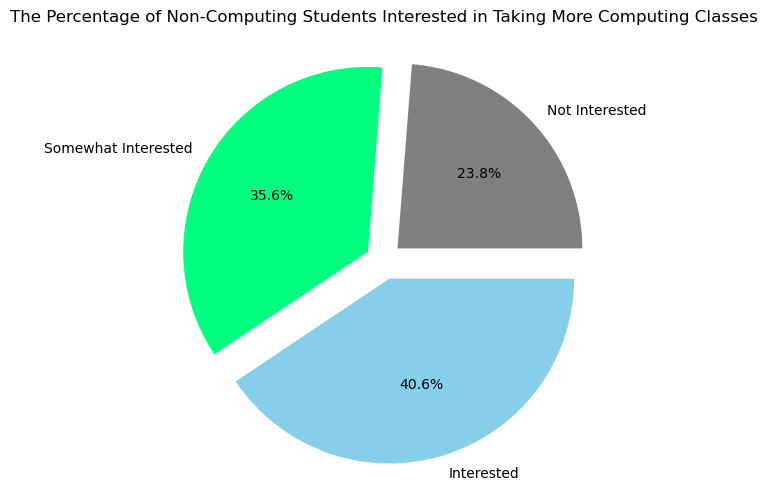

In [115]:
interest_labels = ['Not Interested', 'Somewhat Interested', 'Interested']
interest_values = [23.73, 35.59, 40.58]

explode = (0.1, 0.1, 0.1)

fig, ax = plt.subplots(figsize=(8,6))

ax.pie(interest_values, labels=interest_labels, autopct='%1.1f%%', explode=explode, colors = ['grey','springgreen','skyblue']) #(Pie Charts, 2026)

plt.title("The Percentage of Non-Computing Students Interested in Taking More Computing Classes");

#### Question 5 Analysis -From this pie chart we can see that less than half of non-computing students are interested in taking more computing classes at CCM. To increase enrollment of computer courses, we can focus on the 40.6% that are interested as well as the 35.6% of students who are teetering between not interested and interested. Because the somewhat interested students are in the middle, we can look back at the motivation data and see if the top 4 motivators can influence their decision to continue taking computing classes.

### ------------------------------------------------------------------------------------------------------------------------

### Citations
#### Binowski, N. E. (2026). "Charts with Matplotlib". County College of Morris.ccm.edu
#### Deitel, P. and Deitel, H. M. "Intro to Python for Computer Science and Data Science". Available from: VitalSource Bookshelf, Pearson Education (US), 2019.
#### McDonald, A. "7 Steps to Help You Make Your Matplotlib Bar Chart Beautiful." Towards Data Science. 27 Mar. 2023, https://towardsdatascience.com/7-steps-to-help-you-make-your-matplotlib-bar-charts-beautiful-f87419cb14cb/
#### "pandas.DataFrame.value_counts". pandas. https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.value_counts.html
#### "Rotating Axis Labels in Matplotlib". Python Charts. 17 May 2019, https://www.pythoncharts.com/matplotlib/rotating-axis-labels/
#### “Pie Charts.” Pie Charts - Matplotlib 3.11.2 Documentation, 11 Sept. 2026, https://matplotlib.org/stable/gallery/pie_and_polar_charts/pie_features.html.